# UTS Machine Learning
## Deteksi Intrusi Jaringan pada Dataset NSL-KDD (Klasifikasi Biner: Normal vs Attack)

**Nama:** Riko Nugroho  
**Dataset:** NSL-KDD ([Kaggle](https://www.kaggle.com/datasets/hassan06/nslkdd))  
**File:** `KDDTrain+.txt` (data latih, 125.973 baris) dan `KDDTest+.txt` (data uji, 22.544 baris)

Notebook ini melanjutkan proyek [EDA dan PCA pada NSL-KDD](https://github.com/rik0sec/nsl-kdd-eda-pca-analysis). Fokusnya adalah membangun dan mengevaluasi model machine learning untuk membedakan trafik jaringan **normal** dan **serangan (attack)**.

**Alur notebook:**
1. Pra-pemrosesan data
2. EDA ringkas
3. Pelatihan beberapa model
4. Evaluasi dan confusion matrix
5. Perbandingan model
6. Cross validation dan hyperparameter tuning
7. PCA sebagai eksperimen tambahan
8. Uji coba prediksi
9. Analisis kesalahan: serangan dikenal vs serangan baru
10. Kesimpulan dan keterbatasan

# TAHAP 1. Pra-pemrosesan Data

## 1.1 Menyiapkan data dan import library

Letakkan `KDDTrain+.txt` dan `KDDTest+.txt` di folder `data/` (lihat `data/README.md`). Sel di bawah mencari file di `../data`, `data`, dan `/content` (Google Colab), lalu memeriksa jumlah baris. Jumlah baris harus **125973** (latih) dan **22544** (uji).

In [ ]:
import os

CANDIDATE_DIRS = ['../data', 'data', '/content']   # struktur repo, root repo, Google Colab
DATA_DIR = next((d for d in CANDIDATE_DIRS
                 if os.path.exists(os.path.join(d, 'KDDTrain+.txt'))
                 and os.path.exists(os.path.join(d, 'KDDTest+.txt'))), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        'KDDTrain+.txt dan KDDTest+.txt tidak ditemukan. '
        'Unduh dari Kaggle dan letakkan di folder data/ (lihat data/README.md).'
    )

for fname, expected in [('KDDTrain+.txt', 125973), ('KDDTest+.txt', 22544)]:
    with open(os.path.join(DATA_DIR, fname), encoding='utf-8') as f:
        n_rows = sum(1 for _ in f)
    print(f'{fname:<14}: {n_rows:>7} baris (seharusnya {expected})')
print('Folder data   :', DATA_DIR)

KDDTrain+.txt  :  125973 baris (seharusnya 125973)
KDDTest+.txt   :   22544 baris (seharusnya 22544)
Folder data   : ../data


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)
RANDOM_STATE = 42
print('Library berhasil diimpor.')

Library berhasil diimpor.


## 1.2 Memuat data latih dan data uji

File NSL-KDD tidak memiliki header, jadi nama kolom didefinisikan manual (41 fitur + `label` + `difficulty`).

In [ ]:
TRAIN_PATH = os.path.join(DATA_DIR, 'KDDTrain+.txt')
TEST_PATH = os.path.join(DATA_DIR, 'KDDTest+.txt')

columns = [
    'duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes',
    'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins',
    'logged_in', 'num_compromised', 'root_shell', 'su_attempted',
    'num_root', 'num_file_creations', 'num_shells', 'num_access_files',
    'num_outbound_cmds', 'is_host_login', 'is_guest_login', 'count',
    'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate',
    'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate',
    'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count',
    'dst_host_same_srv_rate', 'dst_host_diff_srv_rate',
    'dst_host_same_src_port_rate', 'dst_host_srv_diff_host_rate',
    'dst_host_serror_rate', 'dst_host_srv_serror_rate',
    'dst_host_rerror_rate', 'dst_host_srv_rerror_rate',
    'label', 'difficulty'
]

for p in (TRAIN_PATH, TEST_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(f'File tidak ditemukan: {p}. Periksa DATA_DIR.')

train_df = pd.read_csv(TRAIN_PATH, header=None, names=columns)
test_df = pd.read_csv(TEST_PATH, header=None, names=columns)

print('Ukuran data latih :', train_df.shape)
print('Ukuran data uji   :', test_df.shape)
display(train_df.head())

Ukuran data latih : (125973, 43)
Ukuran data uji   : (22544, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


## 1.3 Pemeriksaan kualitas data: missing value dan duplikat

Missing value dan duplikat dapat membuat model bias atau terlalu optimis, jadi keduanya diperiksa pada data latih dan data uji.

In [ ]:
for name, d in [('Latih', train_df), ('Uji', test_df)]:
    print(f'--- Data {name} ---')
    print('Total missing value :', int(d.isnull().sum().sum()))
    print('Baris duplikat      :', int(d.duplicated().sum()))
    print()

train_df.info()

--- Data Latih ---
Total missing value : 0
Baris duplikat      : 0

--- Data Uji ---
Total missing value : 0
Baris duplikat      : 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 125973 entries, 0 to 125972
Data columns (total 43 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   duration                     125973 non-null  int64  
 1   protocol_type                125973 non-null  object 
 2   service                      125973 non-null  object 
 3   flag                         125973 non-null  object 
 4   src_bytes                    125973 non-null  int64  
 5   dst_bytes                    125973 non-null  int64  
 6   land                         125973 non-null  int64  
 7   wrong_fragment               125973 non-null  int64  
 8   urgent                       125973 non-null  int64  
 9   hot                          125973 non-null  int64  
 10  num_failed_logins            125973 non-nu

**Interpretasi:** data latih (125.973 baris) dan data uji (22.544 baris) tidak memiliki *missing value* maupun baris duplikat, sehingga tidak diperlukan imputasi atau penghapusan baris. Seluruh 43 kolom terisi penuh.

## 1.4 Membuat label biner (normal vs attack)

Kolom `label` berisi `normal` dan puluhan jenis serangan (neptune, smurf, satan, dll). Karena target UTS ini klasifikasi biner, semua jenis serangan digabung menjadi satu kelas:

- `0` = normal
- `1` = attack

,Latih (jumlah),Latih (%),Uji (jumlah),Uji (%)
0 = normal,67343,53.46,9711,43.08
1 = attack,58630,46.54,12833,56.92


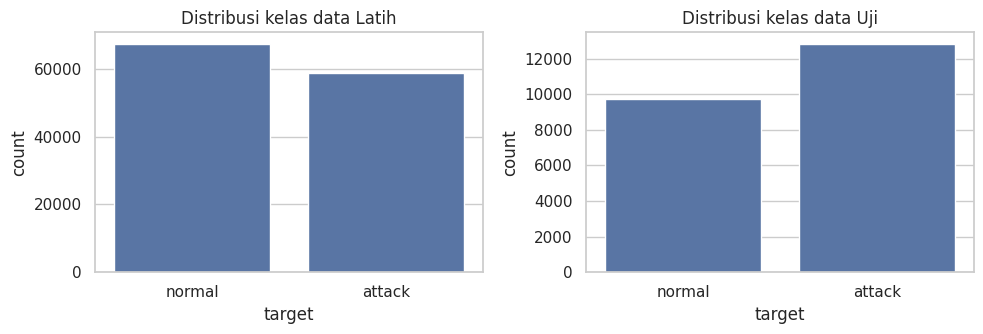

In [ ]:
train_df['target'] = (train_df['label'] != 'normal').astype(int)
test_df['target'] = (test_df['label'] != 'normal').astype(int)

dist = pd.DataFrame({
    'Latih (jumlah)': train_df['target'].value_counts().sort_index(),
    'Latih (%)': (train_df['target'].value_counts(normalize=True).sort_index() * 100).round(2),
    'Uji (jumlah)': test_df['target'].value_counts().sort_index(),
    'Uji (%)': (test_df['target'].value_counts(normalize=True).sort_index() * 100).round(2),
})
dist.index = ['0 = normal', '1 = attack']
display(dist)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, d) in zip(axes, [('Latih', train_df), ('Uji', test_df)]):
    sns.countplot(x='target', data=d, ax=ax)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['normal', 'attack'])
    ax.set_title(f'Distribusi kelas data {name}')
plt.tight_layout()
plt.show()

**Interpretasi:**
- Data latih: normal 67.343 (53,46%) dan attack 58.630 (46,54%). Data uji: normal 9.711 (43,08%) dan attack 12.833 (56,92%).
- Kedua set cukup seimbang, sehingga *accuracy* masih layak dipakai. Tetap saja precision, recall, dan F1 dilaporkan karena kesalahan deteksi punya biaya berbeda (serangan lolos lebih berbahaya daripada alarm palsu).
- Proporsi attack di data uji lebih tinggi daripada di data latih. Ini awal dari perbedaan distribusi antara `KDDTrain+` dan `KDDTest+` yang dibahas lebih lanjut di Tahap 3.
- Sebagai pembanding, model yang selalu menebak "attack" akan mendapat akurasi 56,92% pada data uji. Model yang bermakna harus jauh di atas angka ini.

## 1.5 Memisahkan fitur dan target, serta membuang kolom yang tidak dipakai

- `label` dibuang dari fitur karena menjadi sumber target (kebocoran data jika ikut dipakai).
- `difficulty` dibuang karena hanya skor tingkat kesulitan klasifikasi dari pembuat dataset, bukan karakteristik trafik.
- Kolom konstan (hanya satu nilai unik di data latih) dibuang karena tidak membawa informasi.

In [ ]:
drop_cols = ['label', 'difficulty', 'target']

X_train = train_df.drop(columns=drop_cols)
y_train = train_df['target']
X_test = test_df.drop(columns=drop_cols)
y_test = test_df['target']

# Kolom konstan dicari dari data latih saja
constant_cols = [c for c in X_train.columns if X_train[c].nunique() == 1]
print('Kolom konstan yang dibuang:', constant_cols)

X_train = X_train.drop(columns=constant_cols)
X_test = X_test.drop(columns=constant_cols)
print('Jumlah fitur tersisa:', X_train.shape[1])

Kolom konstan yang dibuang: ['num_outbound_cmds']
Jumlah fitur tersisa: 40


## 1.6 Penanganan nilai ekstrem dan skewness

Pada EDA sebelumnya, `duration`, `src_bytes`, dan `dst_bytes` sangat miring ke kanan dengan rentang nilai yang sangat lebar. Nilai ekstrem pada trafik jaringan bisa jadi merupakan ciri serangan, sehingga **baris outlier tidak dihapus**. Sebagai gantinya, ketiga kolom ditransformasi dengan `log1p` untuk menekan pengaruh skala yang ekstrem tanpa membuang informasi.

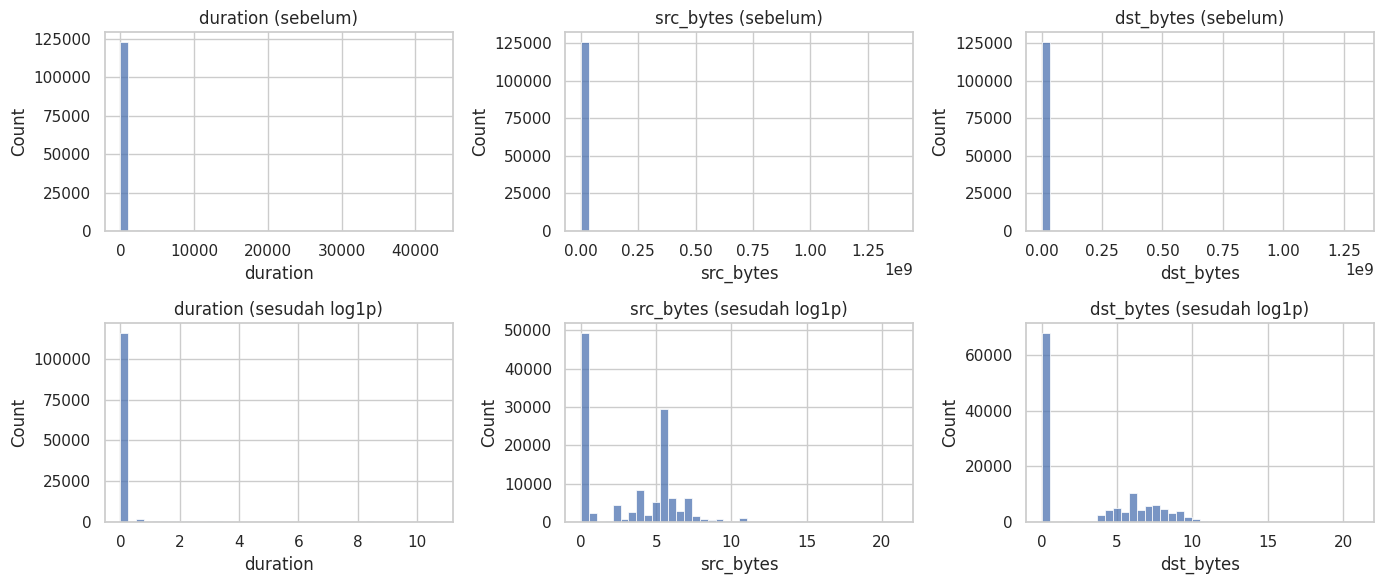

In [ ]:
skewed_cols = [c for c in ['duration', 'src_bytes', 'dst_bytes'] if c in X_train.columns]

X_train = X_train.copy()
X_test = X_test.copy()

# Visualisasi sebelum transformasi
fig, axes = plt.subplots(2, len(skewed_cols), figsize=(14, 6))
for i, c in enumerate(skewed_cols):
    sns.histplot(X_train[c], bins=40, ax=axes[0, i])
    axes[0, i].set_title(f'{c} (sebelum)')

for c in skewed_cols:
    X_train[c] = np.log1p(X_train[c])
    X_test[c] = np.log1p(X_test[c])

for i, c in enumerate(skewed_cols):
    sns.histplot(X_train[c], bins=40, ax=axes[1, i])
    axes[1, i].set_title(f'{c} (sesudah log1p)')
plt.tight_layout()
plt.show()

## 1.7 Encoding variabel kategorikal dan normalisasi fitur numerik

Tiga kolom kategorikal (`protocol_type`, `service`, `flag`) diubah dengan **One-Hot Encoding**. Fitur numerik dinormalisasi dengan **StandardScaler** (rata-rata 0, standar deviasi 1) agar algoritma berbasis jarak seperti KNN dan SVM tidak didominasi fitur berskala besar. Kolom biner (0/1) dibiarkan apa adanya.

Penting: encoder dan scaler **hanya di-fit pada data latih**, lalu diterapkan ke data uji. Ini mencegah data leakage. `handle_unknown='ignore'` dipakai karena data uji bisa memuat kategori `service` yang tidak ada di data latih.

In [ ]:
cat_cols = ['protocol_type', 'service', 'flag']
bin_cols = [c for c in ['land', 'logged_in', 'is_host_login', 'is_guest_login'] if c in X_train.columns]
num_cols = [c for c in X_train.columns if c not in cat_cols + bin_cols]

print('Kategorikal :', cat_cols)
print('Biner       :', bin_cols)
print('Numerik     :', len(num_cols), 'kolom')

# Cek kategori di data uji yang tidak muncul di data latih
for c in cat_cols:
    unseen = set(X_test[c].unique()) - set(X_train[c].unique())
    print(f'Kategori {c} di data uji yang tidak ada di data latih:', unseen if unseen else 'tidak ada')

Kategorikal : ['protocol_type', 'service', 'flag']
Biner       : ['land', 'logged_in', 'is_host_login', 'is_guest_login']
Numerik     : 33 kolom
Kategori protocol_type di data uji yang tidak ada di data latih: tidak ada
Kategori service di data uji yang tidak ada di data latih: tidak ada
Kategori flag di data uji yang tidak ada di data latih: tidak ada


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
        ('bin', 'passthrough', bin_cols),
    ]
)

X_train_prep = preprocessor.fit_transform(X_train)   # fit hanya di data latih
X_test_prep = preprocessor.transform(X_test)         # data uji hanya di-transform

feature_names = preprocessor.get_feature_names_out()
print('Bentuk X_train_prep:', X_train_prep.shape)
print('Bentuk X_test_prep :', X_test_prep.shape)
print('Jumlah fitur akhir :', len(feature_names))

Bentuk X_train_prep: (125973, 121)
Bentuk X_test_prep : (22544, 121)
Jumlah fitur akhir : 121


## 1.8 Validasi hasil pra-pemrosesan

In [ ]:
print('NaN di X_train_prep :', int(np.isnan(X_train_prep).sum()))
print('NaN di X_test_prep  :', int(np.isnan(X_test_prep).sum()))
print('Inf di X_train_prep :', int(np.isinf(X_train_prep).sum()))
print('Jumlah fitur sama   :', X_train_prep.shape[1] == X_test_prep.shape[1])

# Cek hasil standardisasi pada kolom numerik data latih (harusnya mean ~0, std ~1)
n_num = len(num_cols)
print('Rata-rata kolom numerik (data latih):', round(float(X_train_prep[:, :n_num].mean()), 4))
print('Std rata-rata kolom numerik (data latih):', round(float(X_train_prep[:, :n_num].std(axis=0).mean()), 4))

print('\nDistribusi target latih:', dict(y_train.value_counts()))
print('Distribusi target uji  :', dict(y_test.value_counts()))

NaN di X_train_prep : 0
NaN di X_test_prep  : 0
Inf di X_train_prep : 0
Jumlah fitur sama   : True
Rata-rata kolom numerik (data latih): -0.0
Std rata-rata kolom numerik (data latih): 1.0

Distribusi target latih: {0: np.int64(67343), 1: np.int64(58630)}
Distribusi target uji  : {1: np.int64(12833), 0: np.int64(9711)}


### Ringkasan Tahap 1

| Langkah | Tindakan | Alasan |
|---|---|---|
| Missing value dan duplikat | Diperiksa pada data latih dan uji | Menjaga kualitas data |
| Label biner | `normal` = 0, semua serangan = 1 | Sesuai target klasifikasi biner |
| Pembuangan kolom | `label`, `difficulty`, dan kolom konstan | Mencegah kebocoran data dan kolom tanpa informasi |
| Outlier / skewness | Transformasi `log1p` pada `duration`, `src_bytes`, `dst_bytes` | Menekan skala ekstrem tanpa membuang data yang mungkin ciri serangan |
| Encoding | One-Hot pada `protocol_type`, `service`, `flag` | Model hanya menerima angka |
| Normalisasi | StandardScaler pada fitur numerik | Penting untuk KNN, SVM, dan Logistic Regression |
| Anti-leakage | Encoder dan scaler di-fit hanya di data latih | Evaluasi pada data uji tetap jujur |

Variabel yang dipakai di tahap berikutnya: `X_train_prep`, `X_test_prep`, `y_train`, `y_test`, `feature_names`, dan `preprocessor`.

---
# TAHAP 2. EDA Ringkas, Pelatihan Model, dan Evaluasi

Tahap ini memuat: (2.1) EDA ringkas yang menjadi dasar pemilihan algoritma, (2.2) alasan pemilihan algoritma, (2.3) pelatihan lima model, (2.4) perbandingan metrik, (2.5) confusion matrix (TP, TN, FP, FN), dan (2.6) kurva ROC.

## 2.1 EDA ringkas (versi untuk keperluan modeling)

EDA lengkap sudah ada di tugas sebelumnya. Di sini hanya empat grafik yang menjawab: *apakah kelas seimbang, jenis serangan apa yang dominan, protokol mana yang rawan, dan fitur mana yang paling berhubungan dengan serangan?*

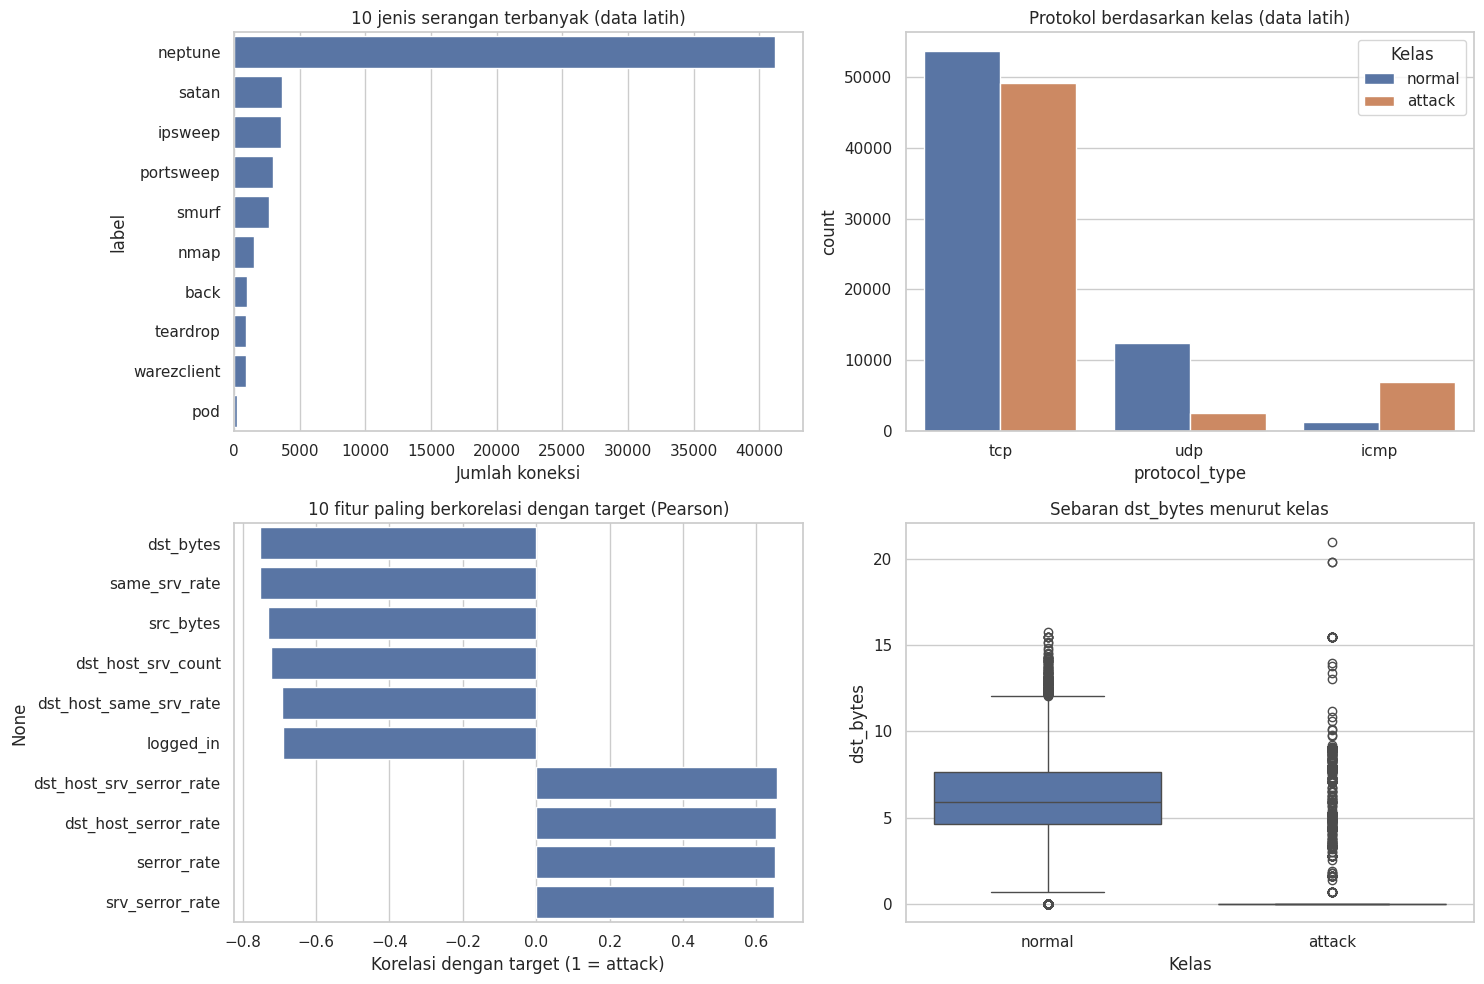

,korelasi
dst_bytes,-0.753
same_srv_rate,-0.752
src_bytes,-0.729
dst_host_srv_count,-0.723
dst_host_same_srv_rate,-0.694
logged_in,-0.690
dst_host_srv_serror_rate,0.655
dst_host_serror_rate,0.652
serror_rate,0.651
srv_serror_rate,0.648


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# (a) 10 label serangan terbanyak pada data latih
top_attacks = train_df.loc[train_df['target'] == 1, 'label'].value_counts().head(10)
sns.barplot(x=top_attacks.values, y=top_attacks.index, ax=axes[0, 0])
axes[0, 0].set_title('10 jenis serangan terbanyak (data latih)')
axes[0, 0].set_xlabel('Jumlah koneksi')

# (b) protokol vs kelas
sns.countplot(data=train_df, x='protocol_type', hue=train_df['target'].map({0: 'normal', 1: 'attack'}), ax=axes[0, 1])
axes[0, 1].set_title('Protokol berdasarkan kelas (data latih)')
axes[0, 1].legend(title='Kelas')

# (c) korelasi fitur numerik dengan target (nilai absolut terbesar)
num_only = X_train[num_cols + bin_cols].copy()
corr_t = num_only.corrwith(y_train).dropna()
top_corr = corr_t.reindex(corr_t.abs().sort_values(ascending=False).head(10).index)
sns.barplot(x=top_corr.values, y=top_corr.index, ax=axes[1, 0])
axes[1, 0].set_title('10 fitur paling berkorelasi dengan target (Pearson)')
axes[1, 0].set_xlabel('Korelasi dengan target (1 = attack)')

# (d) sebaran fitur kunci menurut kelas
feat = top_corr.index[0]
sns.boxplot(x=train_df['target'].map({0: 'normal', 1: 'attack'}), y=X_train[feat], ax=axes[1, 1])
axes[1, 1].set_title(f'Sebaran {feat} menurut kelas')
axes[1, 1].set_xlabel('Kelas')

plt.tight_layout()
plt.show()
display(top_corr.round(3).to_frame('korelasi'))

**Interpretasi:**
- **Jenis serangan:** `neptune` (DoS jenis SYN flood) mendominasi dengan 41.214 koneksi, sekitar 70,3% dari seluruh serangan di data latih. Berikutnya `satan` (3.633), `ipsweep` (3.599), `portsweep` (2.931), dan `smurf` (2.646). Banyak jenis serangan lain sangat jarang, sehingga model cenderung belajar pola `neptune` dengan sangat baik, sedangkan serangan langka sulit dipelajari.
- **Protokol:** ICMP paling rawan secara proporsi (6.982 dari 8.291 koneksi, 84,2% attack), disusul TCP (49.089 dari 102.689, 47,8%) dan UDP (2.559 dari 14.993, 17,1%). TCP menyumbang serangan terbanyak secara jumlah karena volumenya paling besar.
- **Korelasi dengan target:** korelasi negatif terkuat adalah `dst_bytes` (-0,753), `same_srv_rate` (-0,752), `src_bytes` (-0,729), dan `dst_host_srv_count` (-0,723). Korelasi positif terkuat adalah `dst_host_srv_serror_rate` (0,655) dan `serror_rate` (0,651). Artinya koneksi serangan cenderung membawa sedikit byte, jarang berulang ke layanan yang sama, dan punya tingkat error SYN tinggi, pola yang sesuai dengan serangan DoS dan probing.
- Korelasi Pearson hanya mengukur hubungan linear dan bukan sebab-akibat, tetapi fitur-fitur ini kandidat penting bagi model.

## 2.2 Alasan pemilihan algoritma

Masalahnya klasifikasi biner (normal vs attack) pada data tabular dengan sekitar 120 fitur setelah encoding. Lima algoritma dipilih mewakili keluarga yang berbeda supaya perbandingannya bermakna:

| Algoritma | Keluarga | Alasan dipilih |
|---|---|---|
| Logistic Regression | Model linear | Baseline sederhana dan cepat. Jika model kompleks tidak jauh lebih baik, data mungkin hampir terpisah secara linear. |
| K-Nearest Neighbors (KNN) | Berbasis jarak | Tidak mengasumsikan bentuk data. Memanfaatkan normalisasi dari Tahap 1. Prediksi lebih lambat. |
| Decision Tree | Pohon keputusan | Mudah diinterpretasi (aturan if-else), cocok untuk fitur campuran biner, kategorikal (one-hot), dan numerik. |
| Random Forest | Ensemble pohon | Biasanya lebih akurat dan stabil daripada satu pohon, tahan terhadap outlier, dan memberi feature importance. |
| SVM (kernel RBF) | Margin maksimum | Kuat untuk batas keputusan non-linear pada dimensi tinggi. Karena lambat pada 125 ribu baris, SVM dilatih pada **sampel 20.000 baris** (stratified). Batasan ini perlu disebut di laporan. |

## 2.3 Pelatihan model

Semua model dilatih pada `X_train_prep` dan diuji pada `X_test_prep` (`KDDTest+`). Akurasi data latih dihitung pada sampel acak 20.000 baris latih agar cepat. Selisih akurasi latih dan uji dipakai untuk memeriksa **overfitting**.

Sel ini bisa memakan waktu beberapa menit (KNN dan SVM paling lama).

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

y_train_arr = y_train.values
y_test_arr = y_test.values

# Sampel untuk SVM (stratified) dan untuk menghitung akurasi data latih
svm_idx, _ = train_test_split(np.arange(len(y_train_arr)), train_size=20000,
                              stratify=y_train_arr, random_state=RANDOM_STATE)
eval_idx = np.random.RandomState(RANDOM_STATE).choice(len(y_train_arr), 20000, replace=False)

# (model, indeks data latih yang dipakai; None = seluruh data latih)
models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), None),
    'KNN (k=5)':           (KNeighborsClassifier(n_neighbors=5, algorithm='brute', n_jobs=-1), None),
    'Decision Tree':       (DecisionTreeClassifier(random_state=RANDOM_STATE), None),
    'Random Forest':       (RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE), None),
    'SVM (RBF, 20k sampel)': (SVC(kernel='rbf', random_state=RANDOM_STATE), svm_idx),
}

results, preds, scores = [], {}, {}
for name, (model, idx) in models.items():
    Xf, yf = (X_train_prep, y_train_arr) if idx is None else (X_train_prep[idx], y_train_arr[idx])
    t0 = time.time()
    model.fit(Xf, yf)
    fit_time = time.time() - t0

    y_pred = model.predict(X_test_prep)
    s = model.predict_proba(X_test_prep)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test_prep)
    preds[name], scores[name] = y_pred, s

    results.append({
        'Model': name,
        'Akurasi latih': accuracy_score(y_train_arr[eval_idx], model.predict(X_train_prep[eval_idx])),
        'Akurasi uji': accuracy_score(y_test_arr, y_pred),
        'Precision': precision_score(y_test_arr, y_pred),
        'Recall': recall_score(y_test_arr, y_pred),
        'F1-score': f1_score(y_test_arr, y_pred),
        'ROC-AUC': roc_auc_score(y_test_arr, s),
        'Waktu latih (detik)': fit_time,
    })
    print(f'{name:<24} selesai dalam {fit_time:6.1f} detik | akurasi uji = {results[-1]["Akurasi uji"]:.4f}')

Logistic Regression      selesai dalam   10.2 detik | akurasi uji = 0.7517
KNN (k=5)                selesai dalam    0.0 detik | akurasi uji = 0.7806
Decision Tree            selesai dalam    2.8 detik | akurasi uji = 0.8212
Random Forest            selesai dalam   13.4 detik | akurasi uji = 0.7773
SVM (RBF, 20k sampel)    selesai dalam    3.9 detik | akurasi uji = 0.7834


## 2.4 Perbandingan model

Definisi singkat metrik (positif = *attack*):
- **Accuracy**: proporsi prediksi benar dari seluruh data.
- **Precision**: dari yang diprediksi attack, berapa yang benar-benar attack.
- **Recall**: dari seluruh attack asli, berapa yang berhasil terdeteksi. Pada sistem deteksi intrusi, recall rendah berbahaya karena serangan lolos.
- **F1-score**: rata-rata harmonik precision dan recall.
- **ROC-AUC**: kemampuan model memisahkan kedua kelas di semua ambang (1.0 sempurna, 0.5 setara tebakan acak).

,Akurasi latih,Akurasi uji,Precision,Recall,F1-score,ROC-AUC,Waktu latih (detik),Selisih latih-uji
Model,,,,,,,,
Decision Tree,0.9998,0.8212,0.9667,0.7104,0.8190,0.8392,2.8494,0.1786
"SVM (RBF, 20k sampel)",0.9924,0.7834,0.9649,0.6429,0.7716,0.8947,3.9438,0.2090
KNN (k=5),0.9988,0.7806,0.9682,0.6354,0.7673,0.8224,0.0190,0.2182
Random Forest,0.9998,0.7773,0.9685,0.6293,0.7629,0.9526,13.3730,0.2225
Logistic Regression,0.9720,0.7517,0.9148,0.6218,0.7403,0.7850,10.1636,0.2203


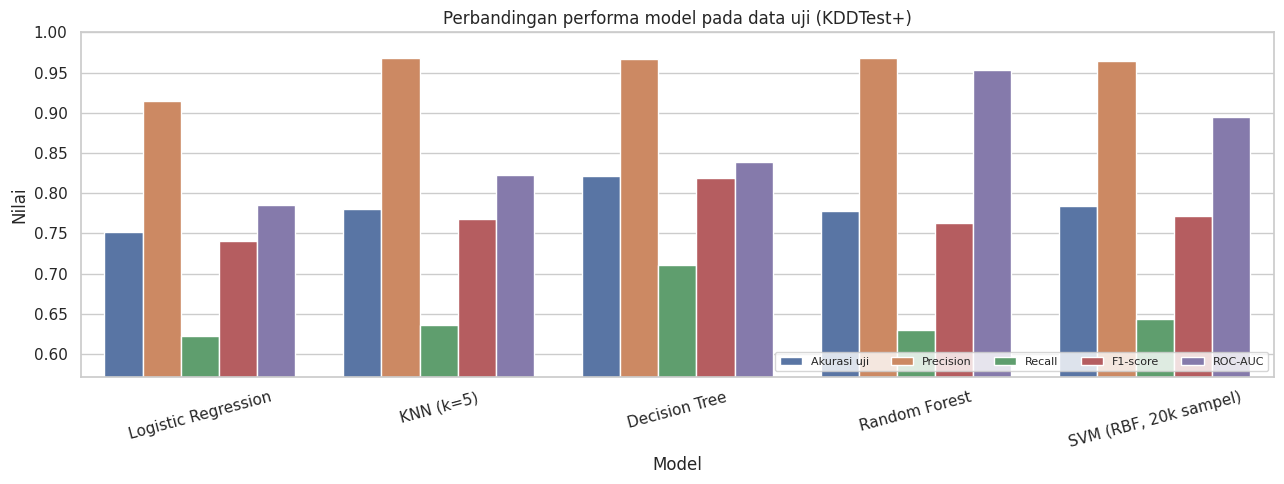

Model terbaik berdasarkan F1-score: Decision Tree


In [ ]:
res_df = pd.DataFrame(results).set_index('Model')
res_df['Selisih latih-uji'] = res_df['Akurasi latih'] - res_df['Akurasi uji']
display(res_df.sort_values('F1-score', ascending=False).round(4))

metrics = ['Akurasi uji', 'Precision', 'Recall', 'F1-score', 'ROC-AUC']
plot_df = res_df[metrics].reset_index().melt(id_vars='Model', var_name='Metrik', value_name='Nilai')
plt.figure(figsize=(13, 5))
sns.barplot(data=plot_df, x='Model', y='Nilai', hue='Metrik')
plt.ylim(max(0, plot_df['Nilai'].min() - 0.05), 1.0)
plt.title('Perbandingan performa model pada data uji (KDDTest+)')
plt.xticks(rotation=15)
plt.legend(loc='lower right', ncol=5, fontsize=8)
plt.tight_layout()
plt.show()

best_name = res_df['F1-score'].idxmax()
print('Model terbaik berdasarkan F1-score:', best_name)

**Interpretasi:**
- **Model terbaik:** Decision Tree (akurasi 0,8212; F1 0,8190). Dibandingkan baseline Logistic Regression (akurasi 0,7517; F1 0,7403), selisihnya +0,0695 pada akurasi dan +0,0787 pada F1. Urutan berikutnya: SVM (0,7834), KNN (0,7806), Random Forest (0,7773).
- **Precision tinggi, recall rendah:** precision seluruh model 0,91 sampai 0,97, tetapi recall hanya 0,62 sampai 0,71. Model jarang salah menuduh trafik normal, namun banyak serangan lolos.
- **ROC-AUC:** Random Forest tertinggi (0,9526), jauh di atas Decision Tree (0,8392). Artinya Random Forest unggul dalam mengurutkan koneksi dari yang paling mencurigakan, tetapi dengan ambang default 0,5 recall-nya lebih rendah. Pengaruh ambang dibahas di bagian 3.6.
- **Selisih akurasi latih dan uji** sebesar 0,18 sampai 0,22 pada semua model. Karena hasil cross validation di Tahap 3 juga sangat tinggi, penyebab utamanya bukan overfitting biasa, melainkan perbedaan distribusi data uji (lihat 3.1 dan 3.9).
- Waktu latih KNN hampir 0 detik karena KNN hanya menyimpan data. Biayanya pindah ke tahap prediksi.

## 2.5 Confusion matrix (TN, FP, FN, TP)

Dengan kelas positif = *attack*:
- **TP**: serangan terdeteksi benar.
- **TN**: trafik normal dikenali sebagai normal.
- **FP**: trafik normal salah dituduh serangan (alarm palsu).
- **FN**: serangan lolos dikira normal. Ini kesalahan paling berbahaya pada deteksi intrusi.

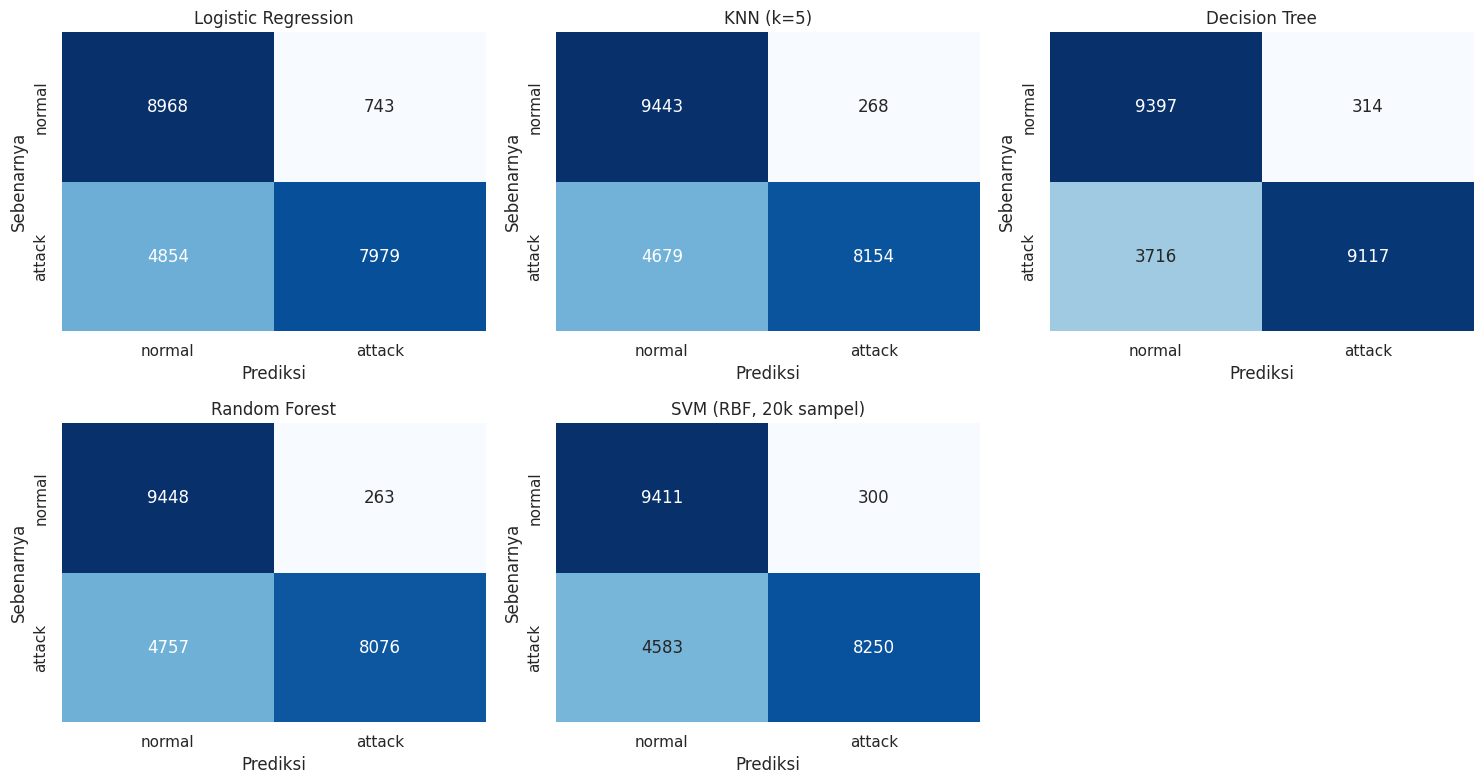

,TN,FP,FN,TP
Model,,,,
Logistic Regression,8968,743,4854,7979
KNN (k=5),9443,268,4679,8154
Decision Tree,9397,314,3716,9117
Random Forest,9448,263,4757,8076
"SVM (RBF, 20k sampel)",9411,300,4583,8250


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
cm_rows = []
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test_arr, y_pred)          # [[TN, FP], [FN, TP]]
    tn, fp, fn, tp = cm.ravel()
    cm_rows.append({'Model': name, 'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp})
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['normal', 'attack'], yticklabels=['normal', 'attack'])
    ax.set_title(name)
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Sebenarnya')
for ax in axes[len(preds):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

display(pd.DataFrame(cm_rows).set_index('Model'))

**Interpretasi:**
- Decision Tree memiliki FN terendah (3.716 serangan lolos, 29,0% dari 12.833 serangan) dan TP tertinggi (9.117). Logistic Regression paling banyak melewatkan serangan (FN 4.854, 37,8%).
- Alarm palsu (FP) terendah dimiliki Random Forest (263, 2,7% dari 9.711 trafik normal) dan KNN (268). Logistic Regression paling banyak memberi alarm palsu (743, 7,7%).
- Pada semua model, FN jauh lebih besar daripada FP. Model cenderung konservatif: lebih baik menganggap normal daripada menuduh serangan. Pada deteksi intrusi ini berisiko karena serangan lolos adalah kesalahan paling mahal.
- Pada data ini, model dengan akurasi tertinggi (Decision Tree) juga memiliki FN terendah, tetapi FP-nya bukan yang terendah. Ada trade-off antara dua jenis kesalahan.

## 2.6 Kurva ROC

Kurva yang lebih dekat ke pojok kiri atas berarti model lebih baik memisahkan normal dan attack.

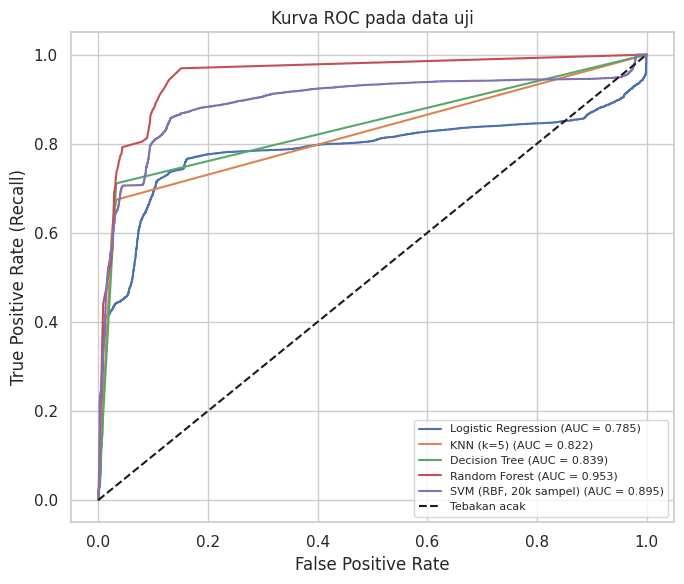

In [ ]:
plt.figure(figsize=(7, 6))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(y_test_arr, s)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test_arr, s):.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Tebakan acak')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.title('Kurva ROC pada data uji')
plt.legend(loc='lower right', fontsize=8)
plt.tight_layout()
plt.show()

## 2.7 Laporan klasifikasi model terbaik

In [ ]:
print('Model:', best_name)
print(classification_report(y_test_arr, preds[best_name], target_names=['normal', 'attack'], digits=4))

Model: Decision Tree
              precision    recall  f1-score   support

      normal     0.7166    0.9677    0.8234      9711
      attack     0.9667    0.7104    0.8190     12833

    accuracy                         0.8212     22544
   macro avg     0.8417    0.8390    0.8212     22544
weighted avg     0.8590    0.8212    0.8209     22544



### Ringkasan Tahap 2
Variabel yang dipakai di Tahap 3 (tuning, cross validation, PCA, uji prediksi): `models`, `preds`, `res_df`, `best_name`, `X_train_prep`, `X_test_prep`, `y_train_arr`, `y_test_arr`, `preprocessor`, `feature_names`.

---
# TAHAP 3. Cross Validation, Hyperparameter Tuning, Analisis Overfitting, PCA, dan Uji Prediksi

Istilah penting:
- **Cross validation (CV)**: data latih dibagi menjadi *k* bagian (fold). Model dilatih pada k-1 bagian dan divalidasi pada satu bagian sisanya, bergiliran sebanyak k kali. Hasilnya rata-rata skor yang lebih andal daripada satu kali pembagian. Di sini dipakai *Stratified 5-Fold* (proporsi kelas tiap fold dijaga).
- **Hyperparameter tuning**: mencari pengaturan model yang tidak dipelajari dari data (misalnya kedalaman pohon, nilai C pada SVM) yang memberi skor terbaik. Dipakai *RandomizedSearchCV* (mencoba kombinasi acak, lebih cepat daripada Grid Search).
- **Overfitting**: model sangat bagus di data latih tetapi buruk di data baru (menghafal). **Underfitting**: model terlalu sederhana sehingga buruk di keduanya.

## 3.1 Cross validation (Stratified 5-Fold) pada data latih

CV dijalankan pada data latih saja. Data uji `KDDTest+` tidak disentuh sehingga tetap menjadi penilaian akhir yang jujur. SVM memakai sampel 20.000 baris seperti di Tahap 2.

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.base import clone

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, (model, idx) in models.items():
    Xf, yf = (X_train_prep, y_train_arr) if idx is None else (X_train_prep[idx], y_train_arr[idx])
    t0 = time.time()
    cv = cross_validate(clone(model), Xf, yf, cv=skf,
                        scoring=['accuracy', 'precision', 'recall', 'f1'], n_jobs=1)
    cv_rows.append({
        'Model': name,
        'CV akurasi (rata-rata)': cv['test_accuracy'].mean(),
        'CV akurasi (std)': cv['test_accuracy'].std(),
        'CV precision': cv['test_precision'].mean(),
        'CV recall': cv['test_recall'].mean(),
        'CV F1': cv['test_f1'].mean(),
        'Akurasi uji (Tahap 2)': res_df.loc[name, 'Akurasi uji'],
    })
    print(f'{name:<24} CV selesai ({time.time()-t0:5.1f} detik)')

cv_df = pd.DataFrame(cv_rows).set_index('Model')
display(cv_df.round(4))

Logistic Regression      CV selesai ( 34.0 detik)
KNN (k=5)                CV selesai (193.7 detik)
Decision Tree            CV selesai ( 11.4 detik)
Random Forest            CV selesai ( 55.1 detik)
SVM (RBF, 20k sampel)    CV selesai ( 13.8 detik)


,CV akurasi (rata-rata),CV akurasi (std),CV precision,CV recall,CV F1,Akurasi uji (Tahap 2)
Model,,,,,,
Logistic Regression,0.9747,0.0011,0.9793,0.9661,0.9726,0.7517
KNN (k=5),0.9974,0.0001,0.9979,0.9966,0.9972,0.7806
Decision Tree,0.9985,0.0002,0.9984,0.9983,0.9984,0.8212
Random Forest,0.9988,0.0002,0.9994,0.9981,0.9988,0.7773
"SVM (RBF, 20k sampel)",0.9926,0.0015,0.9922,0.9919,0.9920,0.7834


**Interpretasi:**
- Akurasi CV berkisar 0,9747 (Logistic Regression) sampai 0,9988 (Random Forest) dengan standar deviasi sangat kecil (maksimum 0,0015), artinya model stabil terhadap pembagian data latih.
- Akurasi pada data uji hanya 0,7517 sampai 0,8212. Selisih besar ini bukan berarti CV salah: fold CV berasal dari distribusi yang sama dengan data latih, sedangkan `KDDTest+` memuat jenis serangan yang tidak ada di data latih. Bagian 3.9 membuktikan hal ini dengan data.

## 3.2 Analisis overfitting: kedalaman Decision Tree

Kedalaman maksimum pohon (`max_depth`) dinaikkan bertahap. Garis akurasi latih dan akurasi uji menunjukkan kapan model underfitting (kedua rendah) dan overfitting (latih tinggi, uji turun atau datar).

,max_depth,Akurasi latih,Akurasi uji
0,1,0.9221,0.7999
1,2,0.9566,0.8153
2,3,0.9747,0.7970
3,4,0.9854,0.8164
4,5,0.9883,0.7940
5,6,0.9931,0.7949
6,8,0.9967,0.7847
7,10,0.9979,0.7846
8,12,0.9986,0.7786
9,15,0.9994,0.7898


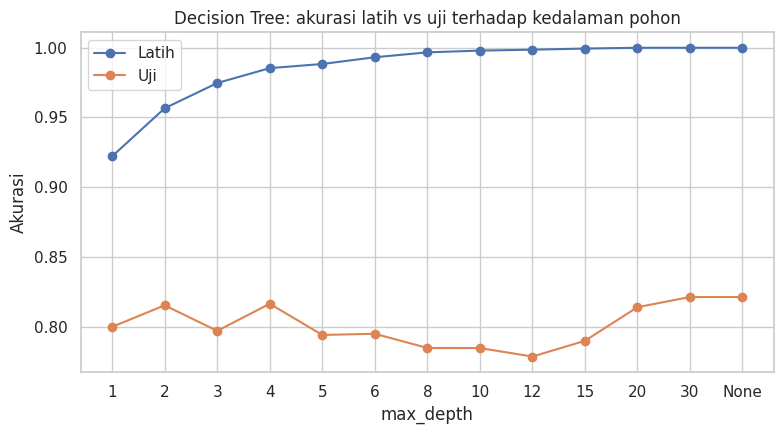

In [ ]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 30, None]
rows = []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train_prep, y_train_arr)
    rows.append({'max_depth': 'None' if d is None else d,
                 'Akurasi latih': m.score(X_train_prep, y_train_arr),
                 'Akurasi uji': m.score(X_test_prep, y_test_arr)})
depth_df = pd.DataFrame(rows)
display(depth_df.round(4))

plt.figure(figsize=(8, 4.5))
plt.plot(depth_df['max_depth'].astype(str), depth_df['Akurasi latih'], marker='o', label='Latih')
plt.plot(depth_df['max_depth'].astype(str), depth_df['Akurasi uji'], marker='o', label='Uji')
plt.xlabel('max_depth')
plt.ylabel('Akurasi')
plt.title('Decision Tree: akurasi latih vs uji terhadap kedalaman pohon')
plt.legend()
plt.tight_layout()
plt.show()

**Interpretasi:**
- Pada `max_depth` = 1 pohon masih underfitting (latih 0,9221; uji 0,7999). Akurasi latih naik terus hingga mendekati 1,0 pada kedalaman 20 ke atas.
- Akurasi uji tidak ikut naik secara teratur: bergerak di kisaran 0,78 sampai 0,82 (terendah 0,7786 pada kedalaman 12). Pohon dengan kedalaman 2 sudah mencapai 0,8153 dan pohon dengan kedalaman 4 mencapai 0,8164. Nilai tertinggi 0,8212 baru muncul pada kedalaman 30 atau tanpa batas, hanya 0,0059 di atas kedalaman 2.
- Jadi memperdalam pohon tidak membuat generalisasi lebih baik, dan membatasi kedalaman juga tidak menutup selisih latih-uji. Ini konsisten dengan penyebab perbedaan distribusi pada data uji, bukan sekadar kompleksitas model.
- Perbedaan antar kedalaman pada data uji sangat kecil, jadi tidak tepat memilih kedalaman hanya dari satu data uji.

## 3.3 Hyperparameter tuning (RandomizedSearchCV)

Tiga model dituning: Decision Tree, Random Forest, dan SVM. Metrik pemilihan adalah **F1-score** (menyeimbangkan precision dan recall) dengan 3-fold CV. Agar cepat, pencarian dilakukan pada sampel acak stratified 30.000 baris data latih, lalu parameter terbaik dilatih ulang pada data latih penuh (SVM tetap pada sampel 20.000 baris). Data uji tidak dipakai untuk memilih parameter.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, loguniform

tune_idx, _ = train_test_split(np.arange(len(y_train_arr)), train_size=30000,
                               stratify=y_train_arr, random_state=RANDOM_STATE)
X_tune, y_tune = X_train_prep[tune_idx], y_train_arr[tune_idx]

search_spaces = {
    'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE), {
        'criterion': ['gini', 'entropy'],
        'max_depth': [5, 8, 10, 12, 15, 20, 30, None],
        'min_samples_leaf': randint(1, 30),
        'min_samples_split': randint(2, 40),
    }),
    'Random Forest': (RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE), {
        'n_estimators': [100, 200, 300],
        'max_depth': [10, 15, 20, 30, None],
        'min_samples_leaf': randint(1, 10),
        'max_features': ['sqrt', 'log2', 0.3],
    }),
    'SVM': (SVC(kernel='rbf', random_state=RANDOM_STATE), {
        'C': loguniform(0.1, 100),
        'gamma': loguniform(1e-4, 1e-1),
    }),
}

best_params, tune_rows = {}, []
for name, (est, space) in search_spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(est, space, n_iter=12, cv=3, scoring='f1',
                            random_state=RANDOM_STATE, n_jobs=1)
    rs.fit(X_tune, y_tune)
    best_params[name] = rs.best_params_
    tune_rows.append({'Model': name, 'F1 CV terbaik': rs.best_score_, 'Parameter terbaik': rs.best_params_})
    print(f'{name:<14} selesai ({time.time()-t0:5.1f} detik)')

display(pd.DataFrame(tune_rows).set_index('Model'))

Decision Tree  selesai (  6.9 detik)
Random Forest  selesai (172.1 detik)
SVM            selesai (426.9 detik)


,F1 CV terbaik,Parameter terbaik
Model,,
Decision Tree,0.994881,"{'criterion': 'entropy', 'max_depth': None, 'm..."
Random Forest,0.997453,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
SVM,0.995046,"{'C': 1.3292918943162166, 'gamma': 0.071144760..."


### 3.3.1 Melatih ulang dengan parameter terbaik dan membandingkan dengan baseline

In [ ]:
tuned_models = {
    'Decision Tree (tuned)': (DecisionTreeClassifier(random_state=RANDOM_STATE, **best_params['Decision Tree']), None),
    'Random Forest (tuned)': (RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE, **best_params['Random Forest']), None),
    'SVM (tuned, 20k sampel)': (SVC(kernel='rbf', random_state=RANDOM_STATE, **best_params['SVM']), svm_idx),
}

tuned_results, tuned_preds, tuned_scores, fitted = [], {}, {}, {}
for name, (model, idx) in tuned_models.items():
    Xf, yf = (X_train_prep, y_train_arr) if idx is None else (X_train_prep[idx], y_train_arr[idx])
    t0 = time.time()
    model.fit(Xf, yf)
    ft = time.time() - t0
    y_pred = model.predict(X_test_prep)
    s = model.predict_proba(X_test_prep)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test_prep)
    tuned_preds[name], tuned_scores[name], fitted[name] = y_pred, s, model
    tuned_results.append({
        'Model': name,
        'Akurasi latih': accuracy_score(y_train_arr[eval_idx], model.predict(X_train_prep[eval_idx])),
        'Akurasi uji': accuracy_score(y_test_arr, y_pred),
        'Precision': precision_score(y_test_arr, y_pred),
        'Recall': recall_score(y_test_arr, y_pred),
        'F1-score': f1_score(y_test_arr, y_pred),
        'ROC-AUC': roc_auc_score(y_test_arr, s),
        'Waktu latih (detik)': ft,
    })

all_df = pd.concat([res_df.drop(columns='Selisih latih-uji'),
                    pd.DataFrame(tuned_results).set_index('Model')])
all_df['Selisih latih-uji'] = all_df['Akurasi latih'] - all_df['Akurasi uji']
display(all_df.sort_values('F1-score', ascending=False).round(4))

# Perubahan akibat tuning
for base, tuned in [('Decision Tree', 'Decision Tree (tuned)'), ('Random Forest', 'Random Forest (tuned)'),
                    ('SVM (RBF, 20k sampel)', 'SVM (tuned, 20k sampel)')]:
    d_acc = all_df.loc[tuned, 'Akurasi uji'] - all_df.loc[base, 'Akurasi uji']
    d_f1 = all_df.loc[tuned, 'F1-score'] - all_df.loc[base, 'F1-score']
    print(f'{base:<24} -> tuned: perubahan akurasi uji {d_acc:+.4f}, perubahan F1 {d_f1:+.4f}')

,Akurasi latih,Akurasi uji,Precision,Recall,F1-score,ROC-AUC,Waktu latih (detik),Selisih latih-uji
Model,,,,,,,,
Decision Tree,0.9998,0.8212,0.9667,0.7104,0.8190,0.8392,2.8494,0.1786
Decision Tree (tuned),0.9987,0.8015,0.9682,0.6734,0.7943,0.8313,1.7297,0.1972
"SVM (RBF, 20k sampel)",0.9924,0.7834,0.9649,0.6429,0.7716,0.8947,3.9438,0.2090
KNN (k=5),0.9988,0.7806,0.9682,0.6354,0.7673,0.8224,0.0190,0.2182
Random Forest,0.9998,0.7773,0.9685,0.6293,0.7629,0.9526,13.3730,0.2225
"SVM (tuned, 20k sampel)",0.9958,0.7768,0.9658,0.6303,0.7628,0.9167,3.1977,0.2190
Random Forest (tuned),0.9998,0.7764,0.9685,0.6277,0.7617,0.9631,39.8907,0.2234
Logistic Regression,0.9720,0.7517,0.9148,0.6218,0.7403,0.7850,10.1636,0.2203


Decision Tree            -> tuned: perubahan akurasi uji -0.0197, perubahan F1 -0.0247
Random Forest            -> tuned: perubahan akurasi uji -0.0009, perubahan F1 -0.0012
SVM (RBF, 20k sampel)    -> tuned: perubahan akurasi uji -0.0066, perubahan F1 -0.0089


**Interpretasi:**
- Skor CV terbaik (F1) sangat tinggi: Decision Tree 0,9949, Random Forest 0,9975, SVM 0,9950. Namun semua model hasil tuning **tidak lebih baik** pada data uji: akurasi berubah -0,0197 (Decision Tree), -0,0009 (Random Forest), dan -0,0066 (SVM); F1 berubah -0,0247, -0,0012, dan -0,0089.
- Selisih akurasi latih-uji juga tidak mengecil (Decision Tree 0,1786 menjadi 0,1972; Random Forest 0,2225 menjadi 0,2234; SVM 0,2090 menjadi 0,2190).
- Tuning memang memperbaiki ROC-AUC pada Random Forest (0,9526 menjadi 0,9631, tertinggi dari seluruh model) dan SVM (0,8947 menjadi 0,9167), artinya kemampuan mengurutkan koneksi membaik, tetapi tidak terlihat pada ambang default.
- Penyebabnya: tuning mengoptimalkan CV pada distribusi data latih, sedangkan data uji berbeda. Hasil ini dilaporkan apa adanya, dan menunjukkan bahwa skor CV tinggi tidak menjamin performa pada pola serangan baru.
- Biaya komputasi pencarian di Colab: Random Forest 172 detik dan SVM 427 detik.

## 3.4 Eksperimen PCA (lanjutan dari tugas EDA/PCA)

PCA dipakai sebagai teknik reduksi dimensi. Di sini diuji apakah mengurangi 121 fitur menjadi komponen utama (95% varians) mengubah performa dan waktu latih. PCA di-fit hanya pada data latih.

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_prep)
X_test_pca = pca.transform(X_test_prep)
print(f'Fitur sebelum PCA: {X_train_prep.shape[1]} | sesudah PCA (95% varians): {X_train_pca.shape[1]}')

pca_models = {
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5, algorithm='brute', n_jobs=-1),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
}
pca_rows = []
for name, m in pca_models.items():
    t0 = time.time(); m.fit(X_train_pca, y_train_arr); ft = time.time() - t0
    yp = m.predict(X_test_pca)
    pca_rows.append({
        'Model': name,
        'Akurasi uji tanpa PCA': res_df.loc[name, 'Akurasi uji'],
        'Akurasi uji dengan PCA': accuracy_score(y_test_arr, yp),
        'F1 tanpa PCA': res_df.loc[name, 'F1-score'],
        'F1 dengan PCA': f1_score(y_test_arr, yp),
        'Waktu latih tanpa PCA (dtk)': res_df.loc[name, 'Waktu latih (detik)'],
        'Waktu latih dengan PCA (dtk)': ft,
    })
pca_df = pd.DataFrame(pca_rows).set_index('Model')
display(pca_df.round(4))

Fitur sebelum PCA: 121 | sesudah PCA (95% varians): 21


,Akurasi uji tanpa PCA,Akurasi uji dengan PCA,F1 tanpa PCA,F1 dengan PCA,Waktu latih tanpa PCA (dtk),Waktu latih dengan PCA (dtk)
Model,,,,,,
Decision Tree,0.8212,0.8026,0.8190,0.7955,2.8494,14.1179
Random Forest,0.7773,0.7764,0.7629,0.7617,13.3730,100.3397
KNN (k=5),0.7806,0.7732,0.7673,0.7567,0.0190,0.0058
Logistic Regression,0.7517,0.7332,0.7403,0.7132,10.1636,1.6111


**Interpretasi:**
- PCA mengurangi fitur dari 121 menjadi 21 komponen (95% varians), sekitar 83% lebih sedikit.
- Namun tidak ada model yang membaik. Akurasi uji berubah: Decision Tree 0,8212 menjadi 0,8026 (-0,0186), Random Forest 0,7773 menjadi 0,7764 (-0,0009), KNN 0,7806 menjadi 0,7732 (-0,0074), Logistic Regression 0,7517 menjadi 0,7332 (-0,0185). F1 menurun dengan pola serupa.
- Waktu latih model berbasis pohon justru lebih lama (Decision Tree 2,8 menjadi 14,1 detik; Random Forest 13,4 menjadi 100,3 detik), karena komponen PCA berupa nilai kontinu yang padat sehingga pohon memeriksa lebih banyak kandidat pemisahan. Logistic Regression lebih cepat (10,2 menjadi 1,6 detik). Waktu diukur satu kali di Colab, jadi hanya indikatif.
- Kesimpulan: pada kasus ini PCA tidak layak dipakai untuk meningkatkan performa, sehingga model akhir memakai fitur asli.
- Catatan: jumlah komponen di sini (21) jauh lebih sedikit daripada di proyek EDA/PCA sebelumnya (82). Kemungkinan besar karena perlakuan encoding berbeda: di proyek itu semua kolom one-hot ikut distandardisasi, sedangkan di sini hanya fitur numerik yang distandardisasi sehingga kolom one-hot menyumbang varians kecil.

## 3.5 Feature importance (Random Forest tuned)

Fitur mana yang paling berpengaruh pada keputusan model? Ini juga membantu menjelaskan karakteristik serangan.

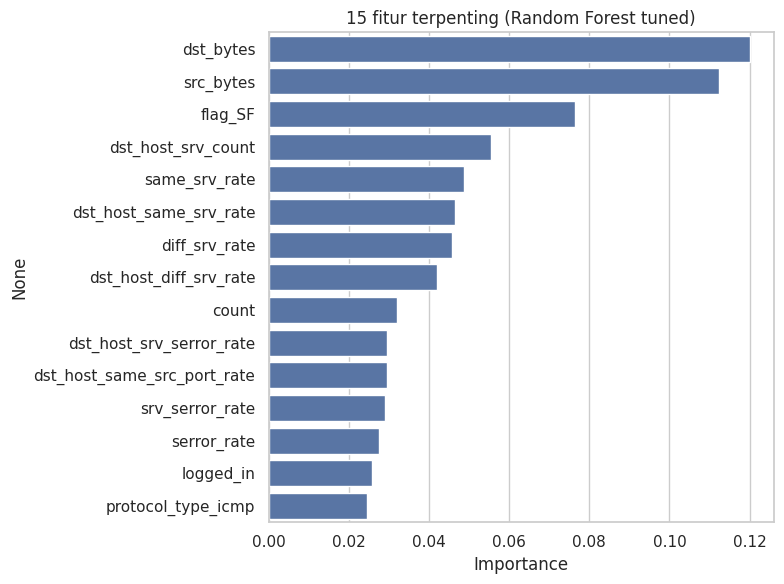

In [ ]:
rf_final = fitted['Random Forest (tuned)']
imp = pd.Series(rf_final.feature_importances_, index=feature_names)
imp.index = [i.split('__', 1)[-1] for i in imp.index]
top_imp = imp.sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=top_imp.values, y=top_imp.index)
plt.title('15 fitur terpenting (Random Forest tuned)')
plt.xlabel('Importance')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

**Interpretasi:**
- Lima fitur terpenting: `dst_bytes` (sekitar 0,12), `src_bytes` (sekitar 0,11), `flag_SF` (sekitar 0,08), `dst_host_srv_count` (sekitar 0,055), dan `same_srv_rate` (sekitar 0,05).
- `dst_bytes` dan `src_bytes` adalah jumlah byte dari tujuan dan sumber. `flag_SF` menandai koneksi yang dimulai dan diakhiri secara normal. `dst_host_srv_count` adalah jumlah koneksi ke layanan yang sama pada host tujuan, dan `same_srv_rate` adalah proporsi koneksi ke layanan yang sama.
- Empat dari lima fitur ini (`dst_bytes`, `src_bytes`, `dst_host_srv_count`, `same_srv_rate`) juga termasuk empat fitur paling berkorelasi dengan target pada EDA (bagian 2.1), sehingga hasilnya konsisten.
- Feature importance bukan bukti sebab-akibat. Nilainya hanya menunjukkan fitur yang paling sering dipakai pohon untuk memisahkan kelas.

## 3.6 Analisis tambahan: ambang keputusan (threshold) dan trade-off recall

Pada deteksi intrusi, serangan yang lolos (FN) lebih berbahaya daripada alarm palsu (FP). Model memberi probabilitas attack, dan ambang 0,5 hanyalah default. Grafik di bawah menunjukkan bagaimana precision dan recall berubah jika ambang diubah. Ini analisis untuk diskusi trade-off, bukan untuk memilih ambang memakai data uji.

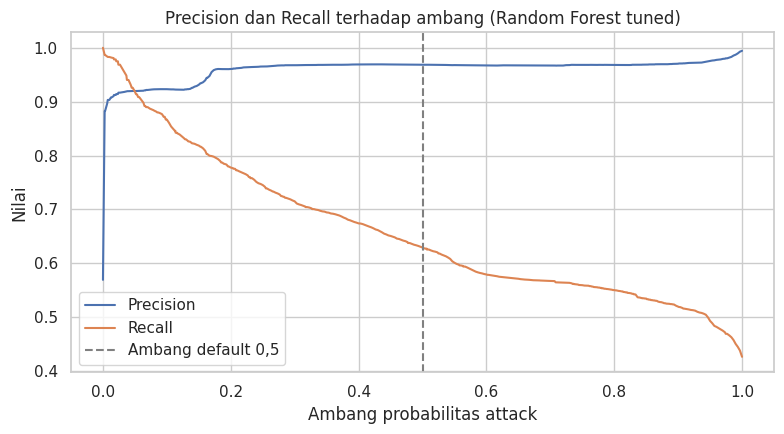

,Akurasi,Precision,Recall,FP,FN
Ambang,,,,,
0.5,0.7773,0.9685,0.6292,263,4758
0.4,0.8022,0.9690,0.6740,277,4183
0.3,0.8241,0.9676,0.7150,307,3658
0.2,0.8553,0.9606,0.7777,409,2853
0.1,0.8830,0.9231,0.8667,926,1711


In [ ]:
from sklearn.metrics import precision_recall_curve

p, r, th = precision_recall_curve(y_test_arr, tuned_scores['Random Forest (tuned)'])
plt.figure(figsize=(8, 4.5))
plt.plot(th, p[:-1], label='Precision')
plt.plot(th, r[:-1], label='Recall')
plt.axvline(0.5, color='gray', linestyle='--', label='Ambang default 0,5')
plt.xlabel('Ambang probabilitas attack')
plt.ylabel('Nilai')
plt.title('Precision dan Recall terhadap ambang (Random Forest tuned)')
plt.legend()
plt.tight_layout()
plt.show()

rows = []
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    yp = (tuned_scores['Random Forest (tuned)'] >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test_arr, yp).ravel()
    rows.append({'Ambang': t, 'Akurasi': accuracy_score(y_test_arr, yp), 'Precision': precision_score(y_test_arr, yp),
                 'Recall': recall_score(y_test_arr, yp), 'FP': fp, 'FN': fn})
display(pd.DataFrame(rows).set_index('Ambang').round(4))

**Interpretasi:** menurunkan ambang dari 0,5 ke 0,1 pada Random Forest (tuned) menaikkan recall dari 0,6292 menjadi 0,8667 dan menurunkan serangan lolos (FN) dari 4.758 menjadi 1.711. Harganya: alarm palsu (FP) naik dari 263 menjadi 926 dan precision turun dari 0,9685 menjadi 0,9231. Akurasi bahkan naik dari 0,7773 menjadi 0,8830 karena error terbesar model ada pada FN.

Sistem keamanan yang tidak boleh kecolongan akan memilih ambang lebih rendah dan menerima lebih banyak alarm palsu. Analisis ini hanya untuk diskusi trade-off. Ambang sebaiknya dipilih memakai data validasi terpisah, bukan data uji.

## 3.7 Pemilihan model akhir dan confusion matrix

Model akhir dipilih dari seluruh model (baseline dan tuned) berdasarkan F1-score pada data uji. Karena F1 menyeimbangkan precision dan recall, ia cocok untuk deteksi intrusi.

**Catatan metodologi:** memilih model berdasarkan data uji berarti data uji ikut menentukan pilihan. Untuk tugas ini hal itu dapat diterima karena `KDDTest+` memang disediakan sebagai pembanding, tetapi sebutkan di laporan bahwa pemilihan dilakukan dengan melihat hasil uji, dan bahwa pemilihan yang lebih ketat memakai data validasi terpisah.

Model akhir: Decision Tree


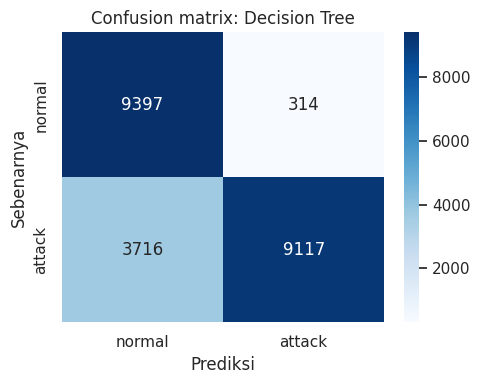

TN = 9397 | FP = 314 | FN = 3716 | TP = 9117

              precision    recall  f1-score   support

      normal     0.7166    0.9677    0.8234      9711
      attack     0.9667    0.7104    0.8190     12833

    accuracy                         0.8212     22544
   macro avg     0.8417    0.8390    0.8212     22544
weighted avg     0.8590    0.8212    0.8209     22544



In [ ]:
final_name = all_df['F1-score'].idxmax()
all_preds = {**preds, **tuned_preds}
print('Model akhir:', final_name)

cm = confusion_matrix(y_test_arr, all_preds[final_name])
tn, fp, fn, tp = cm.ravel()
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['normal', 'attack'], yticklabels=['normal', 'attack'])
plt.xlabel('Prediksi'); plt.ylabel('Sebenarnya'); plt.title(f'Confusion matrix: {final_name}')
plt.tight_layout(); plt.show()
print(f'TN = {tn} | FP = {fp} | FN = {fn} | TP = {tp}')
print()
print(classification_report(y_test_arr, all_preds[final_name], target_names=['normal', 'attack'], digits=4))

**Interpretasi model akhir (Decision Tree):** TN = 9.397, FP = 314, FN = 3.716, TP = 9.117. Precision kelas attack 0,9667 (dari semua yang diprediksi attack, 96,7% benar) dan recall 0,7104 (hanya 71,0% serangan terdeteksi). Sebaliknya trafik normal dikenali dengan baik (recall 0,9677). Sekitar 29% serangan pada data uji lolos, jadi model ini belum layak dipakai sebagai satu-satunya pertahanan.

## 3.8 Uji coba prediksi

Dua uji coba: (a) 10 sampel acak dari data uji, membandingkan label asli dan prediksi model akhir, dan (b) prediksi untuk satu koneksi jaringan "baru" yang dimasukkan sebagai data mentah, yang diproses dengan langkah pra-pemrosesan yang sama seperti data latih.

In [ ]:
final_model = fitted[final_name] if final_name in fitted else models[final_name][0]

def predict_raw(df_raw):
    """Menerima baris data mentah (kolom seperti NSL-KDD), mengembalikan prediksi dan probabilitas/skor."""
    d = df_raw.drop(columns=[c for c in ['label', 'difficulty', 'target'] + constant_cols if c in df_raw.columns]).copy()
    for c in skewed_cols:
        d[c] = np.log1p(d[c])
    d = d[X_train.columns]
    Xp = preprocessor.transform(d)
    pred = final_model.predict(Xp)
    if hasattr(final_model, 'predict_proba'):
        score = final_model.predict_proba(Xp)[:, 1]
    else:
        score = final_model.decision_function(Xp)
    return pred, score

# (a) 10 sampel acak dari data uji
sample = test_df.sample(10, random_state=7)
pred, score = predict_raw(sample)
out = pd.DataFrame({
    'protocol': sample['protocol_type'].values,
    'service': sample['service'].values,
    'label asli': sample['label'].values,
    'kelas asli': np.where(sample['target'].values == 1, 'attack', 'normal'),
    'prediksi': np.where(pred == 1, 'attack', 'normal'),
    'skor': score.round(3),
})
out['benar?'] = np.where(out['kelas asli'] == out['prediksi'], 'ya', 'TIDAK')
display(out)
print('Benar:', int((out['benar?'] == 'ya').sum()), 'dari 10')

,protocol,service,label asli,kelas asli,prediksi,skor,benar?
0,udp,domain_u,normal,normal,normal,0.0,ya
1,tcp,smtp,normal,normal,normal,0.0,ya
2,udp,domain_u,normal,normal,normal,0.0,ya
3,tcp,ftp_data,normal,normal,normal,0.0,ya
4,udp,domain_u,normal,normal,normal,0.0,ya
5,udp,private,snmpguess,attack,normal,0.0,TIDAK
6,tcp,http,normal,normal,normal,0.0,ya
7,udp,private,snmpgetattack,attack,normal,0.0,TIDAK
8,tcp,sunrpc,mscan,attack,attack,1.0,ya
9,tcp,telnet,processtable,attack,normal,0.0,TIDAK


Benar: 7 dari 10


In [ ]:
# (b) Satu koneksi "baru" (data mentah). Contoh: pola mirip serangan SYN flood (banyak koneksi, error rate tinggi)
new_conn = pd.DataFrame([{
    'duration': 0, 'protocol_type': 'tcp', 'service': 'private', 'flag': 'S0', 'src_bytes': 0, 'dst_bytes': 0,
    'land': 0, 'wrong_fragment': 0, 'urgent': 0, 'hot': 0, 'num_failed_logins': 0, 'logged_in': 0,
    'num_compromised': 0, 'root_shell': 0, 'su_attempted': 0, 'num_root': 0, 'num_file_creations': 0,
    'num_shells': 0, 'num_access_files': 0, 'num_outbound_cmds': 0, 'is_host_login': 0, 'is_guest_login': 0,
    'count': 123, 'srv_count': 6, 'serror_rate': 1.0, 'srv_serror_rate': 1.0, 'rerror_rate': 0.0,
    'srv_rerror_rate': 0.0, 'same_srv_rate': 0.05, 'diff_srv_rate': 0.07, 'srv_diff_host_rate': 0.0,
    'dst_host_count': 255, 'dst_host_srv_count': 26, 'dst_host_same_srv_rate': 0.10, 'dst_host_diff_srv_rate': 0.05,
    'dst_host_same_src_port_rate': 0.0, 'dst_host_srv_diff_host_rate': 0.0, 'dst_host_serror_rate': 1.0,
    'dst_host_srv_serror_rate': 1.0, 'dst_host_rerror_rate': 0.0, 'dst_host_srv_rerror_rate': 0.0,
}])
pred_new, score_new = predict_raw(new_conn)
print('Koneksi 1 (pola SYN flood)  ->', 'ATTACK' if pred_new[0] == 1 else 'NORMAL', f'(skor = {score_new[0]:.3f})')

# Koneksi normal: HTTP biasa dengan transfer data dan login berhasil
normal_conn = new_conn.copy()
normal_conn.loc[0, ['service', 'flag', 'src_bytes', 'dst_bytes', 'logged_in', 'count', 'srv_count',
                    'serror_rate', 'srv_serror_rate', 'same_srv_rate', 'diff_srv_rate',
                    'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate',
                    'dst_host_serror_rate', 'dst_host_srv_serror_rate']] = \
    ['http', 'SF', 232, 8153, 1, 5, 5, 0.0, 0.0, 1.0, 0.0, 30, 255, 1.0, 0.0, 0.0]
pred_n, score_n = predict_raw(normal_conn)
print('Koneksi 2 (HTTP biasa)      ->', 'ATTACK' if pred_n[0] == 1 else 'NORMAL', f'(skor = {score_n[0]:.3f})')

Koneksi 1 (pola SYN flood)  -> ATTACK (skor = 1.000)
Koneksi 2 (HTTP biasa)      -> NORMAL (skor = 0.000)


**Interpretasi uji coba prediksi:**
- Dari 10 sampel acak, 7 diprediksi benar. Ketiga kesalahan seluruhnya adalah serangan yang diprediksi normal (FN): `snmpguess`, `snmpgetattack`, dan `processtable`. Ketiga jenis serangan ini tidak ada di data latih (lihat 3.9).
- Koneksi buatan dengan pola SYN flood diprediksi **ATTACK** (skor 1,000) dan koneksi HTTP biasa diprediksi **NORMAL** (skor 0,000).
- Skor tepat 0 atau 1 muncul karena Decision Tree yang ditumbuhkan penuh memiliki daun murni, sehingga skornya bukan probabilitas yang terkalibrasi.

## 3.9 Analisis kesalahan: serangan dikenal vs serangan baru

Pada 3.1 terlihat akurasi CV sangat tinggi, tetapi akurasi uji jauh lebih rendah. Dugaannya: `KDDTest+` memuat jenis serangan yang tidak ada di `KDDTrain+`. Sel berikut mengujinya dengan menghitung recall model akhir secara terpisah untuk serangan **dikenal** (jenisnya juga ada di data latih) dan serangan **baru** (hanya ada di data uji).

,jumlah_koneksi,jenis_serangan,recall
jenis,,,
Baru,3750,17,0.4667
Dikenal,9083,20,0.8111


Serangan baru = 29.22% dari seluruh serangan pada data uji


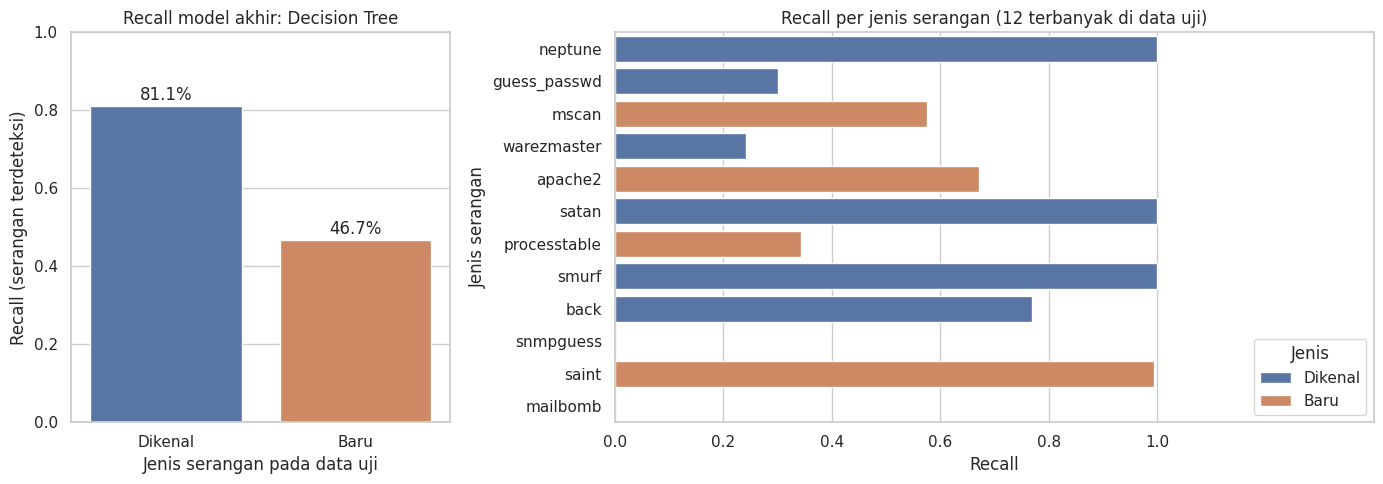

,jenis,jumlah,recall
label,,,
neptune,Dikenal,4657,0.9998
guess_passwd,Dikenal,1231,0.3014
mscan,Baru,996,0.5753
warezmaster,Dikenal,944,0.2415
apache2,Baru,737,0.6716
satan,Dikenal,735,1.0000
processtable,Baru,685,0.3431
smurf,Dikenal,665,1.0000
back,Dikenal,359,0.7688


In [ ]:
# Serangan "dikenal" = jenis serangan yang juga muncul di data latih; "baru" = hanya ada di data uji
seen_labels = set(train_df['label'].unique())
is_attack = (test_df['target'] == 1).values

te_att = test_df.loc[is_attack, ['label']].copy()
te_att['terdeteksi'] = (all_preds[final_name][is_attack] == 1).astype(int)   # 1 = serangan berhasil terdeteksi
te_att['jenis'] = np.where(te_att['label'].isin(seen_labels), 'Dikenal', 'Baru')

ringkas = te_att.groupby('jenis').agg(
    jumlah_koneksi=('label', 'size'),
    jenis_serangan=('label', 'nunique'),
    recall=('terdeteksi', 'mean'),
).round(4)
display(ringkas)
print(f"Serangan baru = {(te_att['jenis'] == 'Baru').mean() * 100:.2f}% dari seluruh serangan pada data uji")

# Recall per jenis serangan (12 jenis terbanyak di data uji)
per_jenis = (te_att.groupby(['label', 'jenis'])
             .agg(jumlah=('label', 'size'), recall=('terdeteksi', 'mean'))
             .reset_index().sort_values('jumlah', ascending=False).head(12))

palette = {'Dikenal': '#4C72B0', 'Baru': '#DD8452'}
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1, 2]})

r = ringkas.reset_index()
sns.barplot(data=r, x='jenis', y='recall', hue='jenis', order=['Dikenal', 'Baru'], palette=palette, dodge=False, legend=False, ax=axes[0])
for i, v in enumerate(r.set_index('jenis').loc[['Dikenal', 'Baru'], 'recall']):
    axes[0].text(i, v + 0.015, f'{v:.1%}', ha='center')
axes[0].set_ylim(0, 1)
axes[0].set_xlabel('Jenis serangan pada data uji')
axes[0].set_ylabel('Recall (serangan terdeteksi)')
axes[0].set_title(f'Recall model akhir: {final_name}')

sns.barplot(data=per_jenis, x='recall', y='label', hue='jenis', hue_order=['Dikenal', 'Baru'], palette=palette, dodge=False, ax=axes[1])
axes[1].set_xlim(0, 1.4)
axes[1].set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Jenis serangan')
axes[1].set_title('Recall per jenis serangan (12 terbanyak di data uji)')
axes[1].legend(title='Jenis', loc='lower right')

plt.tight_layout()
plt.show()
display(per_jenis.round(4).set_index('label'))

**Interpretasi:**
- Data latih memuat 22 jenis serangan, data uji 37 jenis. Terdapat **17 jenis serangan baru** (antara lain `mscan`, `apache2`, `processtable`, `snmpguess`, `saint`, `mailbomb`) yang mencakup 3.750 koneksi atau **29,22%** dari seluruh serangan di data uji.
- Recall untuk serangan dikenal **81,1%**, sedangkan untuk serangan baru hanya **46,7%**. Model hampir tidak mendeteksi `snmpguess` dan `mailbomb` (recall 0), tetapi mendeteksi `saint` dengan baik (99,4%).
- Ini menjelaskan jurang antara CV (sekitar 99%) dan data uji (82%): CV hanya menguji pola yang sudah pernah dilihat, sedangkan data uji juga menguji kemampuan menggeneralisasi ke serangan baru.
- Serangan dikenal pun tidak seragam: `neptune`, `satan`, dan `smurf` terdeteksi hampir sempurna, tetapi `guess_passwd` (30,1%) dan `warezmaster` (24,2%) sering lolos. Keduanya jenis serangan dengan sampel latih sangat sedikit.
- Implikasi: untuk deteksi intrusi nyata, pendekatan terawasi (supervised) saja tidak cukup. Perlu ditambah deteksi anomali atau pembaruan model berkala.

## 3.10 Kesimpulan dan keterbatasan

**Kesimpulan**
1. **Pra-pemrosesan:** data bersih (tanpa missing value dan duplikat), label digabung menjadi biner, kolom konstan (`num_outbound_cmds`) dibuang, fitur `duration`, `src_bytes`, `dst_bytes` ditransformasi `log1p`, fitur kategorikal di-one-hot, fitur numerik distandardisasi, dan semua transformasi di-fit hanya pada data latih (121 fitur akhir).
2. **Model:** lima algoritma dibandingkan (Logistic Regression, KNN, Decision Tree, Random Forest, SVM), ditambah versi hasil tuning.
3. **Model akhir:** Decision Tree dengan akurasi uji 0,8212, precision 0,9667, recall 0,7104, F1 0,8190, dan ROC-AUC 0,8392, unggul dari baseline Logistic Regression (akurasi 0,7517; F1 0,7403).
4. **CV vs data uji:** akurasi CV 0,97 sampai 0,999, tetapi akurasi uji 0,75 sampai 0,82. Penyebab utamanya adalah serangan baru di data uji: recall 81,1% untuk serangan dikenal vs 46,7% untuk serangan baru.
5. **Tuning:** tidak menaikkan akurasi atau F1 di data uji (perubahan -0,0009 sampai -0,0197), walau ROC-AUC Random Forest dan SVM membaik.
6. **PCA:** mengurangi fitur dari 121 menjadi 21, tetapi menurunkan akurasi pada semua model yang diuji dan tidak mempercepat model berbasis pohon.
7. **Trade-off:** pada semua model FN jauh lebih banyak daripada FP. Menurunkan ambang keputusan menaikkan recall (Random Forest tuned: 0,63 menjadi 0,87 pada ambang 0,1) dengan harga lebih banyak alarm palsu.

**Keterbatasan dan saran**
- Model akhir dipilih berdasarkan F1 pada data uji, sehingga data uji ikut menentukan pilihan. Pemilihan yang lebih ketat memakai data validasi terpisah.
- SVM dilatih pada sampel 20.000 baris, dan tuning dilakukan pada sampel 30.000 baris dengan 12 iterasi pencarian, sehingga hasilnya bisa berbeda jika memakai seluruh data atau ruang pencarian lebih besar.
- Sekitar 29% serangan di data uji lolos, sehingga model ini belum cukup sebagai satu-satunya pertahanan.
- Pengembangan lanjutan: gradient boosting (XGBoost atau LightGBM), deteksi anomali untuk serangan baru, klasifikasi multikelas (DoS, Probe, R2L, U2R), penanganan ketidakseimbangan jenis serangan, dan validasi dengan pembagian data yang lebih ketat.